In [ ]:
# Members of group 10:
# Beatrice Zundra Rivera
# Clarence Trebita
# Emmanuel Noel C. Sanguyo
# Ryan Kenewene Aton

# This activity applies the K-Means clustering algorithm to the Mall Customers dataset to identify groups of customers with similar characteristics based on age, annual income, and spending score.
# The activity includes data preprocessing, feature scaling, initial clustering with K = 3, evaluation of different cluster counts using the Elbow Method and Silhouette Score, final cluster 
# visualization, and interpretation of the resulting customer segments.

# Dataset source: Kaggle — [Customer Segmentation Tutorial in Python](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python).
# The dataset contains 200 mall customer records, including customer ID, gender, age, annual income, and spending score. This project uses age,
# annual income, and spending score as the numerical features for K-Means clustering.

import pandas as pd

df = pd.read_excel("Mall_Customers.xlsx")

print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)


Dataset shape: (200, 5)

First 5 rows:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Column names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate rows: 0

Data types:
CustomerID                 int64
Gender                    object
Age                        int64
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object


In [33]:
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nSummary statistics:")
display(df.describe())

Dataset shape: (200, 5)

First 5 rows:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Summary statistics:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [34]:
from sklearn.preprocessing import StandardScaler

# Keep the original dataset unchanged
df_clean = df.copy()

# Select numerical features for clustering
features = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

X = df_clean[features].copy()

# Scale the selected features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Create a DataFrame containing the scaled features
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=features
)


# Save the original dataset as a CSV
df.to_csv("Mall_Customers.csv", index=False)

# Save the selected, scaled features used by K-Means
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=features
)

# Keep CustomerID only to identify each observation.
# CustomerID is not used as a clustering feature.
X_scaled_df.insert(
    0,
    "CustomerID",
    df["CustomerID"].to_numpy()
)

X_scaled_df.to_csv(
    "Preprocessed.csv",
    index=False
)

# Verify both exported files
original_csv = pd.read_csv("Mall_Customers.csv")
preprocessed_csv = pd.read_csv("Preprocessed.csv")

print("Original CSV shape:", original_csv.shape)
print("Original CSV columns:", original_csv.columns.tolist())

print("\nPreprocessed CSV shape:", preprocessed_csv.shape)
print("Preprocessed CSV columns:", preprocessed_csv.columns.tolist())

print("\nFirst 5 rows of preprocessed data:")
display(preprocessed_csv.head())

print("\nScaled feature means (should be close to 0):")
display(preprocessed_csv[features].mean().round(4))

print("\nScaled feature standard deviations (should be close to 1):")
display(preprocessed_csv[features].std().round(4))

print("Original dataset shape:", df.shape)
print("Selected features:", features)
print("\nBefore scaling:")
display(X.describe().round(2))

print("\nAfter scaling:")
display(X_scaled_df.describe().round(2))

print("\nPreprocessed dataset saved successfully!")

Original CSV shape: (200, 5)
Original CSV columns: ['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Preprocessed CSV shape: (200, 4)
Preprocessed CSV columns: ['CustomerID', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

First 5 rows of preprocessed data:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
0,1,-1.424569,-1.738999,-0.434801
1,2,-1.281035,-1.738999,1.195704
2,3,-1.352802,-1.700830,-1.715913
3,4,-1.137502,-1.700830,1.040418
4,5,-0.563369,-1.662660,-0.395980



Scaled feature means (should be close to 0):


Age                      -0.0
Annual Income (k$)       -0.0
Spending Score (1-100)   -0.0
dtype: float64


Scaled feature standard deviations (should be close to 1):


...

Original dataset shape: (200, 5)
Selected features: ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Before scaling:


,Age,Annual Income (k$),Spending Score (1-100)
count,200.00,200.00,200.00
mean,38.85,60.56,50.20
std,13.97,26.26,25.82
min,18.00,15.00,1.00
25%,28.75,41.50,34.75
50%,36.00,61.50,50.00
75%,49.00,78.00,73.00
max,70.00,137.00,99.00



After scaling:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.00,200.00,200.00,200.00
mean,100.50,-0.00,-0.00,-0.00
std,57.88,1.00,1.00,1.00
min,1.00,-1.50,-1.74,-1.91
25%,50.75,-0.72,-0.73,-0.60
50%,100.50,-0.20,0.04,-0.01
75%,150.25,0.73,0.67,0.89
max,200.00,2.24,2.92,1.89



Preprocessed dataset saved successfully!


In [35]:
from sklearn.cluster import KMeans

# Create K-Means model with K = 3
kmeans_3 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Fit the model using scaled features
clusters_3 = kmeans_3.fit_predict(X_scaled)

# Add cluster assignments to a copy of the dataset
df_k3 = df_clean.copy()
df_k3["Cluster"] = clusters_3

# Display every customer's cluster assignment
print("Customer assignments (K = 3):")
display(df_k3)

# Count customers in each cluster
print("\nNumber of customers per cluster:")
display(
    df_k3["Cluster"]
    .value_counts()
    .sort_index()
    .rename("Customer Count")
    .to_frame()
)

# Convert centroids back to the original feature scale
centroids_original = scaler.inverse_transform(
    kmeans_3.cluster_centers_
)

centroids_df = pd.DataFrame(
    centroids_original,
    columns=features
)

centroids_df.index.name = "Cluster"

print("\nCluster centroids (original scale):")
display(centroids_df.round(2))

# Save the clustering results
df_k3.to_csv("Mall_Customers_K3_Results.csv", index=False)

print("Results saved to Mall_Customers_K3_Results.csv")

Customer assignments (K = 3):


c:\Users\Emmanuel C. Sanguyo\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,0
1,2,Male,21,15,81,0
2,3,Female,20,16,6,0
3,4,Female,23,16,77,0
4,5,Female,31,17,40,0
...,...,...,...,...,...,...
195,196,Female,35,120,79,1
196,197,Female,45,126,28,2
197,198,Male,32,126,74,1
198,199,Male,32,137,18,1



Number of customers per cluster:


,Customer Count
Cluster,
0,68
1,41
2,91



Cluster centroids (original scale):


,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,25.84,42.75,53.65
1,32.85,87.34,79.98
2,51.27,61.80,34.21


Results saved to Mall_Customers_K3_Results.csv


c:\Users\Emmanuel C. Sanguyo\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Emmanuel C. Sanguyo\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Emmanuel C. Sanguyo\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Emmanuel C. Sanguyo\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: User

,K,Inertia (SSE),Silhouette Score
0,2,389.3862,0.3355
1,3,295.2122,0.3578
2,4,205.2251,0.4040
3,5,168.2476,0.4166
4,6,133.8684,0.4284
5,7,117.0116,0.4172
6,8,103.8733,0.4082
7,9,93.0929,0.4177
8,10,82.3852,0.4066


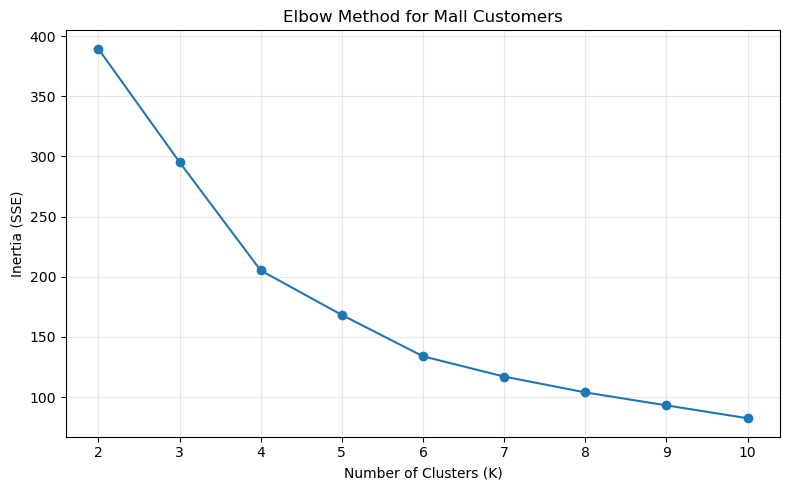

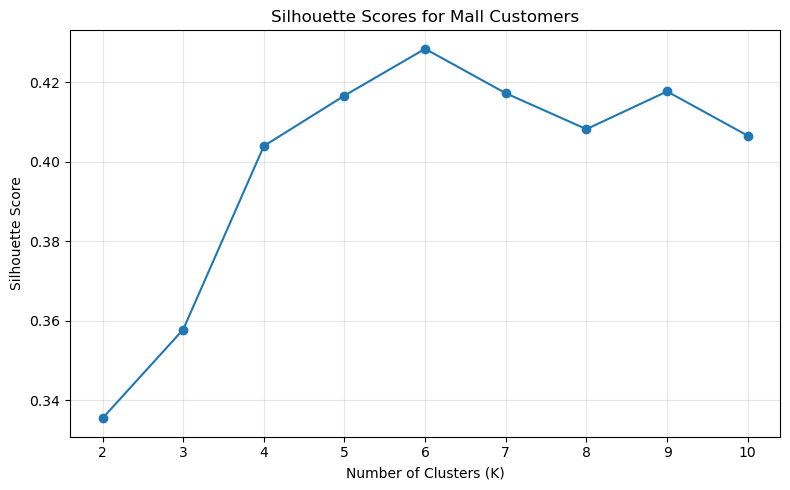

Best K by silhouette score: 6
Highest silhouette score: 0.4284


In [36]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Test K values from 2 to 10
k_values = range(2, 11)

inertias = []
silhouette_scores = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    # Elbow method: within-cluster sum of squares
    inertias.append(model.inertia_)

    # Silhouette score: cluster separation and cohesion
    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

# Display the results
results = pd.DataFrame({
    "K": list(k_values),
    "Inertia (SSE)": inertias,
    "Silhouette Score": silhouette_scores
})

display(results.round(4))

# Elbow graph
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker="o")
plt.title("Elbow Method for Mall Customers")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (SSE)")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Silhouette graph
plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_scores, marker="o")
plt.title("Silhouette Scores for Mall Customers")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Highest silhouette score among tested K values
best_index = silhouette_scores.index(max(silhouette_scores))
best_k_silhouette = list(k_values)[best_index]

print("Best K by silhouette score:", best_k_silhouette)
print(
    "Highest silhouette score:",
    round(silhouette_scores[best_index], 4)
)

Final Cluster Summary (K = 6):


c:\Users\Emmanuel C. Sanguyo\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,Customer_Count,Average_Age,Average_Income,Average_Spending,Percentage
Cluster,,,,,
0,45,56.33,54.27,49.07,22.5
1,39,26.79,57.10,48.13,19.5
2,33,41.94,88.94,16.97,16.5
3,39,32.69,86.54,82.13,19.5
4,23,25.00,25.26,77.61,11.5
5,21,45.52,26.29,19.38,10.5


Final Cluster Centroids:


,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,56.33,54.27,49.07
1,26.79,57.10,48.13
2,41.94,88.94,16.97
3,32.69,86.54,82.13
4,25.00,25.26,77.61
5,45.52,26.29,19.38


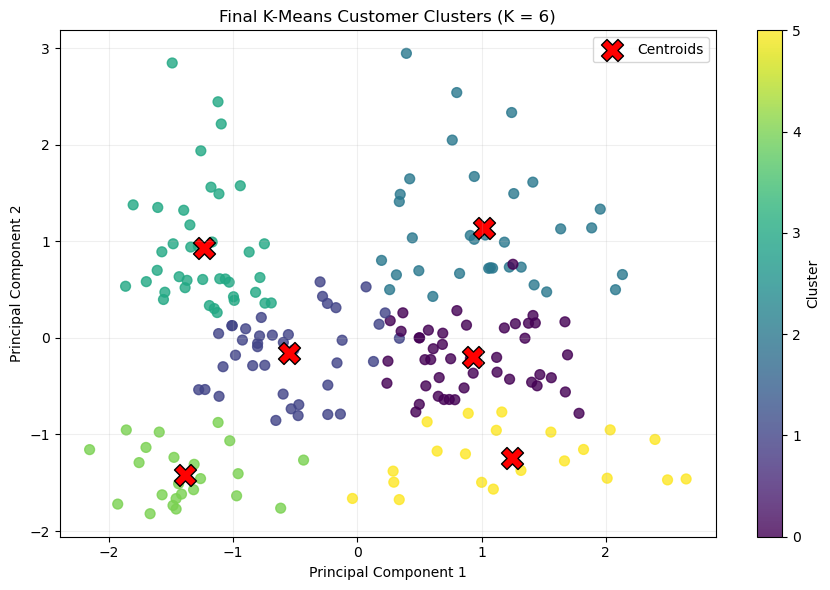

Final clustering files saved.
PCA variance explained: 77.57 %


In [37]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd

# Train the final K-Means model
final_kmeans = KMeans(
    n_clusters=6,
    random_state=42,
    n_init=10
)

final_labels = final_kmeans.fit_predict(X_scaled)

# Add cluster assignments
df_final = df_clean.copy()
df_final["Cluster"] = final_labels

# Cluster counts and percentages
cluster_summary = (
    df_final.groupby("Cluster")
    .agg(
        Customer_Count=("Cluster", "size"),
        Average_Age=("Age", "mean"),
        Average_Income=("Annual Income (k$)", "mean"),
        Average_Spending=("Spending Score (1-100)", "mean")
    )
)

cluster_summary["Percentage"] = (
    cluster_summary["Customer_Count"] / len(df_final) * 100
)

print("Final Cluster Summary (K = 6):")
display(cluster_summary.round(2))

# Convert centroids back to original feature units
centroids = scaler.inverse_transform(
    final_kmeans.cluster_centers_
)

centroids_df = pd.DataFrame(
    centroids,
    columns=features
)
centroids_df.index.name = "Cluster"

print("Final Cluster Centroids:")
display(centroids_df.round(2))

# PCA visualization using all three scaled features
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

centroids_pca = pca.transform(final_kmeans.cluster_centers_)

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=final_labels,
    cmap="viridis",
    s=50,
    alpha=0.8
)

plt.scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    marker="X",
    s=250,
    c="red",
    edgecolors="black",
    label="Centroids"
)

plt.title("Final K-Means Customer Clusters (K = 6)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.colorbar(scatter, label="Cluster")
plt.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

# Save final results
df_final.to_csv("Mall_Customers_Final_Clusters.csv", index=False)
cluster_summary.to_csv("Mall_Customers_Cluster_Summary.csv")

print("Final clustering files saved.")
print(
    "PCA variance explained:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)